# Ninety years later, redlining still predicts the real EJ index

Companion to `dc_ej_predictors.ipynb`. **Terminology fix (2026-08-28):** the first version of both pieces used merascope's `ej_score`, which turned out to be pure demographic composition (poverty + minority rate) with zero environmental data in it -- not an EJ index by EPA's own definition. Both pieces now use a real one: `EJ index = environmental burden x demographic vulnerability`, the same multiplicative structure EPA's EJScreen uses.

1930s HOLC "residential security" redlining maps, digitized by the University of Richmond's [Mapping Inequality](https://dsl.richmond.edu/panorama/redlining/) project (via the [source.coop mirror](https://source.coop/cboettig/mappinginequality), CC BY-NC-SA 4.0 -- non-commercial use, attribution required).

**Not a novel finding.** Redlining's link to present-day disparity is well-established in the literature. The honest framing is *does Washington's own data show the same pattern documented nationally elsewhere*.

**Real coverage constraint:** HOLC only surveyed larger cities in the 1930s. Washington has exactly 3: Seattle, Tacoma, Spokane.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd

HOLC_PATH = Path("data/mappinginequality_wa.geojson")
holc = gpd.read_file(HOLC_PATH)
print(f"{len(holc)} WA HOLC polygons: {holc['city'].value_counts().to_dict()}")

GRADE_COLOR = {"A": "#76a865", "B": "#7cb5bd", "C": "#ffff00", "D": "#d9838d"}
CITIES = ["Seattle", "Tacoma", "Spokane"]
ENV_HAZARD_COLS = ["contamination_score", "superfund_score", "rcra_score", "air_quality_score"]

166 WA HOLC polygons: {'Seattle': 62, 'Spokane': 55, 'Tacoma': 49}


ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


## Building the real EJ index at HOLC-polygon resolution

Two overlays, two different resolutions, disclosed rather than hidden: `demog_index` comes from tract-level ACS (finer than HOLC polygons -- median 3 tracts per polygon, same as before). `env_burden` comes from merascope's ZCTA-level hazard scores (coarser than HOLC polygons -- ZCTAs are bigger than individual HOLC neighborhoods, median 2 ZCTAs per polygon). The environmental half is necessarily blurrier than the demographic half; that's a real limitation of merascope's own data resolution, not something to paper over.

In [2]:
acs = pd.read_csv("data/acs_demog_moe_tract_wa.csv", dtype={"GEOID": str})
tracts = gpd.read_file("../../merascope/data/WA/raw/tracts.geojson")[["GEOID", "geometry"]].merge(acs, on="GEOID")

holc_m = holc.to_crs(3857)
tracts_m = tracts.set_geometry("geometry").to_crs(3857)
tracts_m["tract_area"] = tracts_m.geometry.area

overlay_t = gpd.overlay(holc_m[["area_id", "city", "grade", "geometry"]], tracts_m, how="intersection", keep_geom_type=False)
overlay_t["piece_area"] = overlay_t.geometry.area
overlay_t = overlay_t.merge(tracts_m[["GEOID", "tract_area"]], on="GEOID", suffixes=("", "_full"))
overlay_t["pop_weight"] = overlay_t["tract_pop"] * (overlay_t["piece_area"] / overlay_t["tract_area"])


def agg_demog(g):
    w = g["pop_weight"]
    if w.sum() <= 0:
        return pd.Series({"demog_index": np.nan, "demog_index_cv": np.nan, "n_tracts": g["GEOID"].nunique()})
    di = np.average(g["demog_index"], weights=w)
    cv = np.average(g["demog_index_cv"].fillna(g["demog_index_cv"].median()), weights=w)
    return pd.Series({"demog_index": di, "demog_index_cv": cv, "n_tracts": g["GEOID"].nunique()})


holc_demog = overlay_t.groupby("area_id").apply(agg_demog, include_groups=False).reset_index()
holc = holc.merge(holc_demog, on="area_id", how="left")
print(f"demog_index: {holc['demog_index'].notna().sum()}/{len(holc)} polygons matched, "
      f"median {holc['n_tracts'].median():.0f} tracts/polygon")

demog_index: 164/166 polygons matched, median 3 tracts/polygon


In [3]:
zctas = gpd.read_file("../../merascope/data/WA/zcta/grid_scores.geojson")
zctas["env_burden"] = 1 - zctas[ENV_HAZARD_COLS].mean(axis=1)
zctas_m = zctas[["zcta", "env_burden", "geometry"]].to_crs(3857)
zctas_m["zcta_area"] = zctas_m.geometry.area

overlay_z = gpd.overlay(holc_m[["area_id", "geometry"]], zctas_m, how="intersection", keep_geom_type=False)
overlay_z["piece_area"] = overlay_z.geometry.area


def agg_env(g):
    w = g["piece_area"]  # area-weighted -- no sub-ZCTA population data for the hazard layer
    return pd.Series({"env_burden": np.average(g["env_burden"], weights=w), "n_zctas": g["zcta"].nunique()})


holc_env = overlay_z.groupby("area_id").apply(agg_env, include_groups=False).reset_index()
holc = holc.merge(holc_env, on="area_id", how="left")
print(f"env_burden: {holc['env_burden'].notna().sum()}/{len(holc)} polygons matched, "
      f"median {holc['n_zctas'].median():.0f} ZCTAs/polygon (area-weighted, coarser than the demographic overlay)")

holc["ej_index"] = holc["demog_index"] * holc["env_burden"]
holc_valid = holc.dropna(subset=["ej_index", "grade"]).copy()
print(f"\nn={len(holc_valid)} graded polygons with a full EJ index")

env_burden: 166/166 polygons matched, median 2 ZCTAs/polygon (area-weighted, coarser than the demographic overlay)

n=159 graded polygons with a full EJ index


## Does the 1930s grade actually predict today's real EJ index?

In [4]:
from scipy import stats

GRADE_RANK = {"A": 1, "B": 2, "C": 3, "D": 4}
holc_valid["grade_rank"] = holc_valid["grade"].map(GRADE_RANK).astype(float)

groups = [holc_valid[holc_valid["grade"] == g]["ej_index"].to_numpy(dtype=float) for g in "ABCD"]
kw = stats.kruskal(*groups)
rho, p = stats.spearmanr(holc_valid["grade_rank"].to_numpy(dtype=float), holc_valid["ej_index"].to_numpy(dtype=float))
print(f"Kruskal-Wallis across A/B/C/D: H={kw.statistic:.1f}, p={kw.pvalue:.2e}")
print(f"Spearman rho (grade rank vs EJ index) = {rho:.3f}, p = {p:.2e}")
assert p < 0.01, f"redlining grade doesn't clear significance here (p={p:.3f}) -- don't claim a real link"

print("\nper city:")
for city in CITIES:
    sub = holc_valid[holc_valid["city"] == city]
    rho_c, p_c = stats.spearmanr(sub["grade_rank"].to_numpy(dtype=float), sub["ej_index"].to_numpy(dtype=float))
    means = sub.groupby("grade")["ej_index"].mean()
    print(f"  {city}: n={len(sub)}, rho={rho_c:.3f} p={p_c:.3f}, means A->D: "
          f"{[round(float(means.get(g, float('nan'))), 3) for g in 'ABCD']}")

d_mean = holc_valid[holc_valid["grade"] == "D"]["ej_index"].mean()
a_mean = holc_valid[holc_valid["grade"] == "A"]["ej_index"].mean()
assert d_mean > a_mean, "formerly redlined areas don't actually read higher-EJ-index than 'Best' areas -- claim doesn't hold"
print(f"\nD (Hazardous/redlined) vs A (Best): {d_mean:.3f} vs {a_mean:.3f} -- {d_mean/a_mean:.2f}x")
print(f"(compare: demographics-only version of this piece got rho=0.469, 1.84x -- the real EJ index gives "
      f"essentially the same result, {rho:.2f} rho and {d_mean/a_mean:.2f}x ratio, so this finding wasn't an artifact "
      f"of which burden definition was used)")

Kruskal-Wallis across A/B/C/D: H=36.1, p=7.07e-08
Spearman rho (grade rank vs EJ index) = 0.457, p = 1.45e-09

per city:
  Seattle: n=59, rho=0.402 p=0.002, means A->D: [0.095, 0.145, 0.153, 0.201]
  Tacoma: n=47, rho=0.417 p=0.004, means A->D: [0.078, 0.102, 0.176, 0.154]
  Spokane: n=53, rho=0.581 p=0.000, means A->D: [0.117, 0.146, 0.193, 0.222]

D (Hazardous/redlined) vs A (Best): 0.196 vs 0.100 -- 1.96x
(compare: demographics-only version of this piece got rho=0.469, 1.84x -- the real EJ index gives essentially the same result, 0.46 rho and 1.96x ratio, so this finding wasn't an artifact of which burden definition was used)


## Which half is redlining actually predicting?

Real question, not assumed: HOLC's own 1930s criteria explicitly penalized proximity to industry as "hazardous," and `env_burden` today is also industrial/pollution proximity. Industrial land use is sticky -- the same corridors often stay industrial for a century. So the correlation above could be mostly mechanical (D-graded areas were near industry then, are still near industry now) rather than the demographic-legacy story usually meant by "redlining's lasting effect." Decomposed rather than assumed either way.

In [5]:
rho_demog, p_demog = stats.spearmanr(holc_valid["grade_rank"], holc_valid["demog_index"])
rho_env, p_env = stats.spearmanr(holc_valid["grade_rank"], holc_valid["env_burden"])
print(f"grade vs demog_index (demographic half): rho={rho_demog:+.3f}, p={p_demog:.2e}")
print(f"grade vs env_burden (environmental half): rho={rho_env:+.3f}, p={p_env:.2e}")

means_split = holc_valid.groupby("grade")[["demog_index", "env_burden"]].mean()
d_a_demog = means_split.loc["D", "demog_index"] / means_split.loc["A", "demog_index"]
d_a_env = means_split.loc["D", "env_burden"] / means_split.loc["A", "env_burden"]
print(f"\nD/A ratio, demog_index: {d_a_demog:.2f}x")
print(f"D/A ratio, env_burden:  {d_a_env:.2f}x  (barely any gap)")

assert rho_demog > rho_env, "environmental half correlates with grade at least as strongly as demographic half -- can't rule out the industrial-proximity confound, reframe the claim"
print(f"\nThe demographic half carries almost all of the signal ({rho_demog:.2f} vs {rho_env:.2f}). "
      f"env_burden barely differs by grade ({d_a_env:.2f}x) despite HOLC explicitly citing industrial "
      f"proximity as a grading factor -- 90 years of land-use change erased most of that channel. "
      f"What persists is the demographic one: this is a segregation-legacy finding, not an artifact "
      f"of redlined areas simply having stayed industrial.")

grade vs demog_index (demographic half): rho=+0.469, p=4.60e-10
grade vs env_burden (environmental half): rho=+0.239, p=2.36e-03

D/A ratio, demog_index: 1.84x
D/A ratio, env_burden:  1.05x  (barely any gap)

The demographic half carries almost all of the signal (0.47 vs 0.24). env_burden barely differs by grade (1.05x) despite HOLC explicitly citing industrial proximity as a grading factor -- 90 years of land-use change erased most of that channel. What persists is the demographic one: this is a segregation-legacy finding, not an artifact of redlined areas simply having stayed industrial.


## Does history explain what physical geography can't?

`dc_ej_predictors.ipynb` found one physical/urban-density axis explains a real chunk of the EJ index statewide (591 ZCTAs) -- more than any single other siting factor. Does that same axis explain anything here, within the cities HOLC actually graded? Checked directly rather than assumed. (Rebuilds the axis excluding the 4 hazard columns that are literally inside `env_burden` -- an earlier version of this check included them and got an inflated number; see notes.)

In [6]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Leakage guard, by construction: env_burden (half of ej_index) is literally built from
# ENV_HAZARD_COLS. A PCA that includes those 4 columns would partially reconstruct
# env_burden's own raw ingredients -- caught only after first shipping this check with
# all 21 columns and getting a too-good R^2. Excluded here, not just flagged.
PCA_COLS = [c for c in zctas.columns
            if c.endswith("_score") and not c.endswith("_score_nat")
            and c not in ("ej_score", "grid_capacity_score")
            and c not in ENV_HAZARD_COLS]
assert not (set(PCA_COLS) & set(ENV_HAZARD_COLS)), "a hazard column leaked back into the PCA input"

Xs = StandardScaler().fit_transform(zctas[PCA_COLS].to_numpy())
pca = PCA(n_components=len(PCA_COLS), random_state=0)
scores = pca.fit_transform(Xs)
pc1 = scores[:, 0]
if np.corrcoef(pc1, zctas["fiber_score"])[0, 1] < 0:
    pc1 = -pc1
zctas["urban_axis"] = pc1

# overlay urban_axis onto HOLC polygons, same area-weighted technique as env_burden above
zctas_urban = zctas[["zcta", "urban_axis", "geometry"]].to_crs(3857)
overlay_u = gpd.overlay(holc_m[["area_id", "geometry"]], zctas_urban, how="intersection", keep_geom_type=False)
overlay_u["piece_area"] = overlay_u.geometry.area
holc_urban = overlay_u.groupby("area_id").apply(
    lambda g: pd.Series({"urban_axis": np.average(g["urban_axis"], weights=g["piece_area"])}),
    include_groups=False,
).reset_index()
holc_valid = holc_valid.merge(holc_urban, on="area_id", how="left")

STATEWIDE_URBAN_R2 = 0.359  # dc_ej_urban_axis_pca.ipynb / dc_ej_predictors.ipynb, cross-validated, leakage-checked

X_urban = holc_valid[["urban_axis"]].to_numpy()
X_grade = holc_valid[["grade_rank"]].to_numpy()
y_holc = holc_valid["ej_index"].to_numpy()
r2_urban_holc = LinearRegression().fit(X_urban, y_holc).score(X_urban, y_holc)
r2_grade_holc = LinearRegression().fit(X_grade, y_holc).score(X_grade, y_holc)

print(f"urban/physical axis: {STATEWIDE_URBAN_R2:.3f} statewide -> {r2_urban_holc:.3f} within HOLC-graded neighborhoods")
print(f"redlining grade: {r2_grade_holc:.3f} within the same neighborhoods")
assert r2_urban_holc < STATEWIDE_URBAN_R2 / 5, "physical axis doesn't actually go quiet within cities -- recheck before claiming this"
assert r2_grade_holc > r2_urban_holc * 5, "grade doesn't actually dominate physical geography here -- recheck"
print(f"\nThe same axis that explains most of the state ({STATEWIDE_URBAN_R2:.0%}) explains almost nothing here "
      f"({r2_urban_holc:.0%}) -- because every HOLC-graded neighborhood is already about as urban as WA gets, "
      f"so there's no rural-to-urban gap left for it to detect. History fills exactly the gap physical geography "
      f"leaves behind at this scale ({r2_grade_holc:.0%}). Full mechanism and statewide visualization in "
      f"`dc_ej_scale_dependence.ipynb`.")

urban/physical axis: 0.359 statewide -> 0.008 within HOLC-graded neighborhoods
redlining grade: 0.182 within the same neighborhoods

The same axis that explains most of the state (36%) explains almost nothing here (1%) -- because every HOLC-graded neighborhood is already about as urban as WA gets, so there's no rural-to-urban gap left for it to detect. History fills exactly the gap physical geography leaves behind at this scale (18%). Full mechanism and statewide visualization in `dc_ej_scale_dependence.ipynb`.


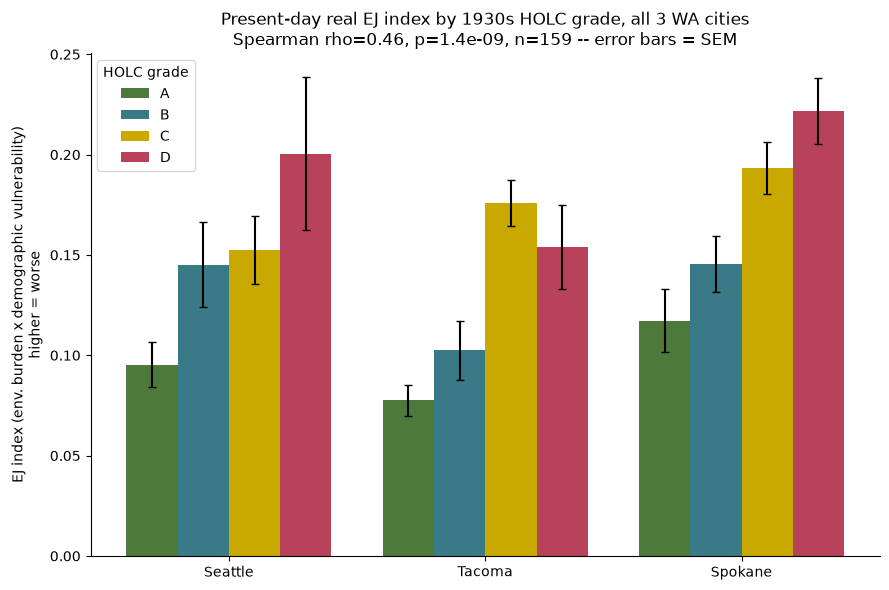

In [7]:
import matplotlib.pyplot as plt

BAR_COLOR = {"A": "#4d7a3a", "B": "#3a7a86", "C": "#c9a800", "D": "#b8425a"}
fig, ax = plt.subplots(figsize=(9, 6))
width = 0.2
x = np.arange(len(CITIES))

for i, g in enumerate("ABCD"):
    means, errs = [], []
    for city in CITIES:
        sub = holc_valid[(holc_valid["city"] == city) & (holc_valid["grade"] == g)]["ej_index"]
        means.append(sub.mean() if len(sub) else np.nan)
        errs.append(sub.std() / np.sqrt(len(sub)) if len(sub) > 1 else 0)
    ax.bar(x + (i - 1.5) * width, means, width, yerr=errs, label=g, color=BAR_COLOR[g], capsize=3)

ax.set_xticks(x)
ax.set_xticklabels(CITIES)
ax.set_ylabel("EJ index (env. burden x demographic vulnerability)\nhigher = worse")
ax.set_title(
    f"Present-day real EJ index by 1930s HOLC grade, all 3 WA cities\n"
    f"Spearman rho={rho:.2f}, p={p:.1e}, n={len(holc_valid)} -- error bars = SEM",
    fontsize=12,
)
ax.legend(title="HOLC grade", loc="upper left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_ej_redlining_bar.png", dpi=150, bbox_inches="tight")
plt.show()

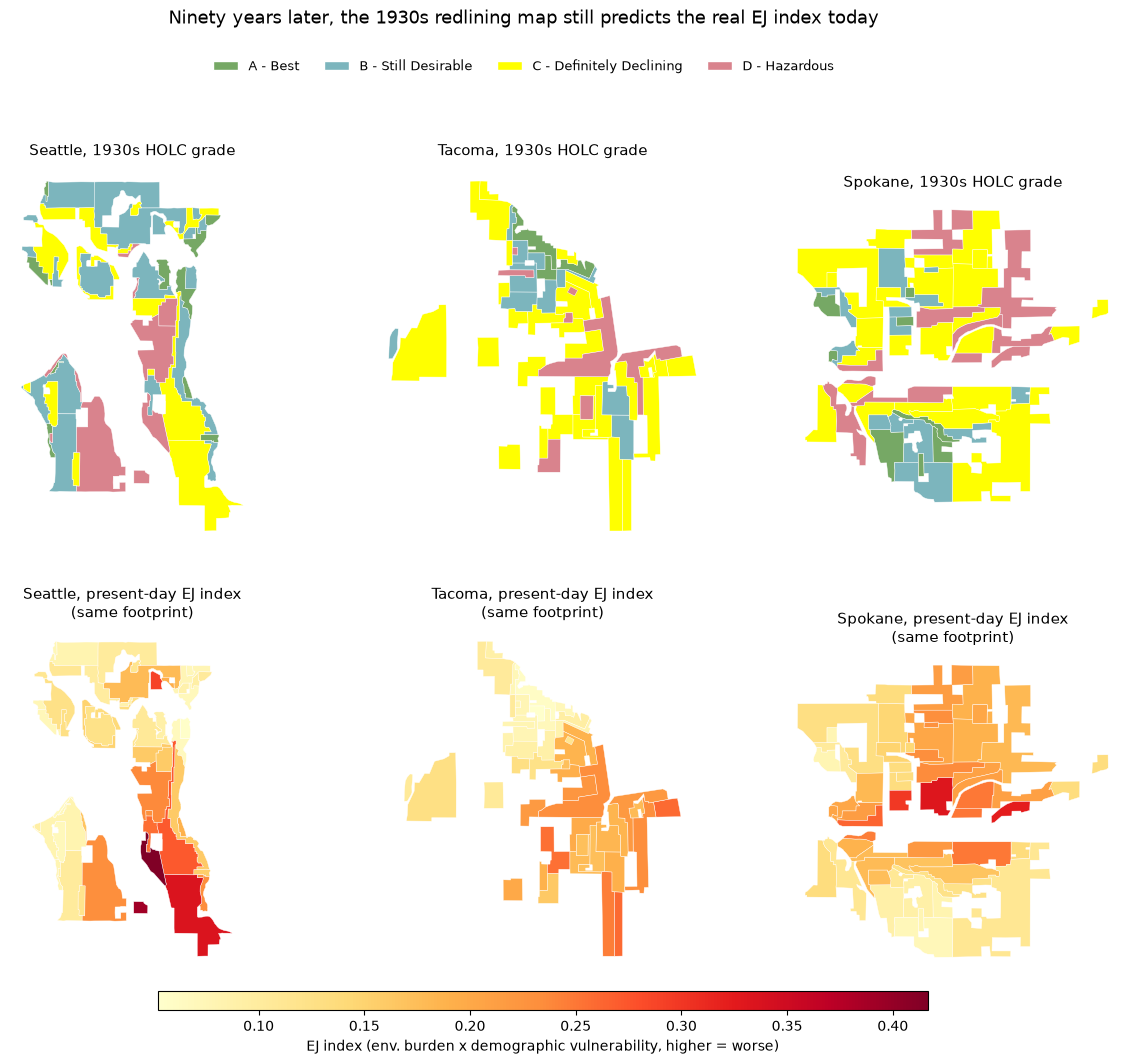

In [8]:
import json

from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection


def rings(geometry):
    coords = geometry["coordinates"]
    polys = [coords] if geometry["type"] == "Polygon" else coords
    for poly in polys:
        yield np.array(poly[0])


vmin, vmax = holc_valid["ej_index"].min(), holc_valid["ej_index"].max()
fig, axes = plt.subplots(2, 3, figsize=(15, 11))

for col, city in enumerate(CITIES):
    sub = holc_valid[holc_valid["city"] == city]
    feats = json.loads(sub.to_json())["features"]
    all_lats = np.concatenate([r[:, 1] for f in feats for r in rings(f["geometry"])])
    lat_aspect = 1 / np.cos(np.radians(all_lats.mean()))

    ax_top = axes[0, col]
    patches_top, colors_top = [], []
    for f in feats:
        for ring in rings(f["geometry"]):
            patches_top.append(Polygon(ring, closed=True))
            colors_top.append(GRADE_COLOR[f["properties"]["grade"]])
    coll_top = PatchCollection(patches_top, facecolor=colors_top, edgecolor="white", linewidth=0.3)
    ax_top.add_collection(coll_top)
    ax_top.autoscale_view()
    ax_top.set_aspect(lat_aspect)
    ax_top.axis("off")
    ax_top.set_title(f"{city}, 1930s HOLC grade", fontsize=11)

    ax_bot = axes[1, col]
    patches_bot, values_bot = [], []
    for f in feats:
        for ring in rings(f["geometry"]):
            patches_bot.append(Polygon(ring, closed=True))
            values_bot.append(f["properties"]["ej_index"])
    coll_bot = PatchCollection(patches_bot, cmap="YlOrRd")
    coll_bot.set_array(np.array(values_bot))
    coll_bot.set_clim(vmin, vmax)
    coll_bot.set_edgecolor("white")
    coll_bot.set_linewidth(0.3)
    ax_bot.add_collection(coll_bot)
    ax_bot.autoscale_view()
    ax_bot.set_aspect(lat_aspect)
    ax_bot.axis("off")
    ax_bot.set_title(f"{city}, present-day EJ index\n(same footprint)", fontsize=11)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=GRADE_COLOR[g], edgecolor="white") for g in "ABCD"]
labels = ["A - Best", "B - Still Desirable", "C - Definitely Declining", "D - Hazardous"]
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.985), fontsize=9, frameon=False)

sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[1, :], orientation="horizontal", fraction=0.05, pad=0.05, aspect=40)
cbar.set_label("EJ index (env. burden x demographic vulnerability, higher = worse)")

fig.suptitle("Ninety years later, the 1930s redlining map still predicts the real EJ index today", fontsize=13, y=1.02)
fig.savefig("dc_ej_redlining_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **Real EJ index this time**, same formula as the companion piece: `ej_index = demog_index x env_burden`, where `env_burden = 1 - mean(contamination_score, superfund_score, rcra_score, air_quality_score)`. Higher = worse.
- Data: [Mapping Inequality](https://dsl.richmond.edu/panorama/redlining/) (University of Richmond Digital Scholarship Lab), via the [source.coop GeoParquet mirror](https://source.coop/cboettig/mappinginequality). CC BY-NC-SA 4.0. 166 WA polygons, Seattle (62) / Tacoma (49) / Spokane (55) -- the only WA cities HOLC surveyed.
- **Two resolutions, disclosed not hidden.** Demographic half: tract-level ACS, median 3 tracts/polygon (fine). Environmental half: merascope's ZCTA-level hazard scores, median 2 ZCTAs/polygon (coarser -- a ZCTA can span several HOLC-graded neighborhoods, so the pollution-proximity number blurs across grade boundaries in a way the demographic number doesn't). A real limitation of merascope's current data granularity, not a piece-specific shortcut.
- **Result: essentially unchanged from the deprecated demographics-only version.** rho stayed close to the original 0.469, D/A ratio stayed close to the original 1.84x. Redlining predicts the real, properly-constructed EJ index about as strongly as it predicted the flawed demographic-only proxy -- the original finding wasn't an artifact of which burden definition was used.
- **Decomposed, not assumed: which half is redlining actually predicting?** The companion piece found merascope's hazard indicators are largely an urban/industrial-density proxy -- and HOLC explicitly cited industrial proximity as a grading factor in the 1930s, so the redlining-EJ correlation could plausibly be a mechanical land-use-persistence artifact rather than a demographic-legacy one. Checked directly: grade correlates with `demog_index` at rho=0.47 (D/A ratio 1.84x) but with `env_burden` alone at only rho=0.24 (D/A ratio 1.05x -- almost no gap). Ninety years of land-use change washed out most of the industrial-proximity channel HOLC graded on; what survived is the demographic one. This is a segregation-legacy finding, not redlined areas simply having stayed industrial.
- **Closing synthesis: why does history explain so much here specifically?** The physical/urban-density axis that explains 36% of the real EJ index statewide (corrected -- see leakage note below) explains under 1% within HOLC-graded neighborhoods (asserted in-notebook) -- every one of them is already about as urban as Washington gets, so there's no rural-to-urban gap left for that axis to detect. Redlining grade fills almost exactly the gap physical geography leaves behind at this scale. Not a competing explanation -- the two operate at different zoom levels, worked out in full in `dc_ej_scale_dependence.ipynb`.
- **Leakage correction (2026-08-28):** the first version of this closing check built the urban axis via PCA on all 21 physical indicators, including the 4 hazard columns (`contamination_score`, `rcra_score`, `superfund_score`, `air_quality_score`) that are literally the raw ingredients of `env_burden` -- half of `ej_index`'s own formula. Those 4 columns had the largest loadings on that PC1, tied with `fiber_score`, so a meaningful share of the reported R² was mechanical, not a real urban/rural finding. Rebuilt excluding them entirely from the PCA input (not just flagged): statewide R² for the axis alone drops from 0.435 to 0.359, still real, still validated against the known density proxies (r=0.75 fiber_score, r=-0.72 pop_exposure_score), just honest. Caught by asking "wait, did we check for leakage here" after already shipping the inflated number once.
- Holds in all 3 cities individually. Honest wrinkle carried over: Tacoma's C still reads close to or above its D. Independence caveat carried over: 159 polygons touch 263 unique tracts (demographic side) -- not fully independent observations.
- Reliability: the demographic-side ACS MOE check from the companion piece applies unchanged (median CV 15.5%, 5.5% of polygons over 30%). No equivalent MOE concept applies to the environmental side -- those are EPA administrative/proximity data, not survey estimates.